# EDA Rectificadores - Evolución del consumo de Formación (SCADA)

**Objetivo.** Antes de construir o plantear cualquier modelo, la idea principal sería que
entendiéramos cómo evoluciona el consumo de energía de los rectificadores de Formación (por día,
por hora y por día de la semana) y qué tan confiables son sus lecturas.

**Contexto:** En la formación de baterías, los rectificadores convierten la corriente alterna de
la red en corriente continua para hacer la primera carga eléctrica de cada batería. El archivo
trae, hora por hora, la lectura del **contador de energía** de 3 rectificadores, tomada del SCADA
(el sistema de monitoreo de planta). Un contador funciona como el medidor de luz de una casa: el
número siempre crece, y el consumo de una hora es la diferencia entre dos lecturas seguidas.

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split

In [2]:
REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

In [3]:
from data_utils.bivaraite_boxplot import plot_segmented_boxplot
from data_utils.triple_plot import normality_report

In [4]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
ALPHA = 0.05
DATA_PATH = REPO_ROOT / "data" / "SCADA_Base_de_Datos_FA.xlsx"
FA_PATH = REPO_ROOT / "data" / "Base_de_Datos.xlsx"
SHEET = "Dataset 1"
ZONA_HORARIA = "America/Bogota"

WH_POR_KWH = 1000
HORAS_DIA = 24
UMBRAL_OPERACION_KWH = 50  # por debajo de esto en una hora, el rectificador se considera apagado

NOMBRES = {"RECTIFICADOR 1": "R1", "RECTIFICADOR 2": "R2", "RECTIFICADOR 3": "R3"}
RECT = list(NOMBRES.values())
DIAS_SEMANA = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
SABADO, DOMINGO = 5, 6  # posición del día en la semana (lunes = 0)
COLORES = {
    "R1": "#1f4e79",
    "R2": "#d17a22",
    "R3": "#2e8b57",
    "Total": "#555555",
    "train": "#1f4e79",
    "test": "#c0392b",
    "atipico": "#c0392b",
}


def aplicar_estilo() -> None:
    """Fija el estilo común de los gráficos del notebook."""
    sns.set_theme(style="whitegrid", context="notebook")
    plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titleweight": "bold"})


aplicar_estilo()
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Carga de datos

In [5]:
hojas = pd.read_excel(DATA_PATH, sheet_name=None)
print("Hojas disponibles en el archivo:", list(hojas))

crudo = hojas[SHEET]
print(f"Filas: {len(crudo)} | Columnas: {crudo.shape[1]}")
display(crudo.head())
display(crudo.tail(3))

Hojas disponibles en el archivo: ['Dataset 1']
Filas: 2208 | Columnas: 4


C:\Users\Diego Andres\Documents\UNIVERSIDAD\RETO CATCH\clarios_app\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,t_stamp,RECTIFICADOR 1,RECTIFICADOR 2,RECTIFICADOR 3
0,2026-07-01 19:24:49.746,22747664384,23587129344,20015581184
1,2026-07-01 20:24:49.746,22747664384,23587129344,20015659008
2,2026-07-01 21:24:49.746,22747664384,23587129344,20015728640
3,2026-07-01 22:24:49.746,22747664384,23587129344,20015792128
4,2026-07-01 23:24:49.746,22747664384,23587129344,20015853568


,t_stamp,RECTIFICADOR 1,RECTIFICADOR 2,RECTIFICADOR 3
2205,2026-10-01 16:24:49.746,23812409344,24665444352,20922343424
2206,2026-10-01 17:24:49.746,23812417536,24665448448,20922474496
2207,2026-10-01 18:24:49.746,23812419584,24665448448,20922605568


## 2. Tipos de datos y validación del esquema

In [6]:
def perfil_tipos(df: pd.DataFrame) -> pd.DataFrame:
    """Resume el tipo asignado por pandas y los tipos de Python presentes en cada columna.

    Args:
        df: Tabla a inspeccionar.

    Returns:
        Una fila por columna con el tipo de pandas, los tipos encontrados y los nulos.
    """
    filas = []
    for columna in df.columns:
        tipos = df[columna].dropna().map(lambda v: type(v).__name__).value_counts()
        filas.append(
            {
                "columna": columna,
                "tipo_pandas": str(df[columna].dtype),
                "tipos_python": ", ".join(f"{t} ({n})" for t, n in tipos.items()) or "(vacía)",
                "nulos": int(df[columna].isna().sum()),
            }
        )
    return pd.DataFrame(filas).set_index("columna")


display(perfil_tipos(crudo))

lecturas = crudo.rename(columns={"t_stamp": "t_lectura", **NOMBRES})
lecturas["t_lectura"] = pd.to_datetime(lecturas["t_lectura"])
print(f"Primera lectura: {lecturas['t_lectura'].min()}")
print(f"Última lectura:  {lecturas['t_lectura'].max()}")
print("Minuto y segundo de las lecturas:", lecturas["t_lectura"].dt.strftime("%M:%S.%f").unique())

,tipo_pandas,tipos_python,nulos
columna,,,
t_stamp,datetime64[us],Timestamp (2208),0
RECTIFICADOR 1,int64,int (2208),0
RECTIFICADOR 2,int64,int (2208),0
RECTIFICADOR 3,int64,int (2208),0


Primera lectura: 2026-07-01 19:24:49.746000
Última lectura:  2026-10-01 18:24:49.746000
Minuto y segundo de las lecturas: <ArrowStringArray>
['24:49.746000']
Length: 1, dtype: str


### 2.1 Reglas del esquema

Las reglas revisan la mecánica de las lecturas: que no falten, que lleguen una por hora y que
los contadores nunca retrocedan (un contador que baja indicaría un reinicio o un error).

In [7]:
def regla(
    nombre: str,
    cumple: pd.Series | np.ndarray,
    aplica: pd.Series | np.ndarray | None = None,
) -> dict[str, object]:
    """Evalúa una regla de validación sobre los casos en los que aplica.

    Args:
        nombre: Descripción de la regla.
        cumple: Verdadero en los casos que cumplen la regla.
        aplica: Verdadero en los casos donde la regla tiene sentido; por defecto, todos.

    Returns:
        Diccionario con la regla, los casos evaluados, los que fallan y el resultado.
    """
    cumple_arr = np.asarray(cumple, dtype=bool)
    aplica_arr = np.ones_like(cumple_arr) if aplica is None else np.asarray(aplica, dtype=bool)
    evaluadas = int(aplica_arr.sum())
    fallas = int((aplica_arr & ~cumple_arr).sum())
    return {
        "regla": nombre,
        "casos_evaluados": evaluadas,
        "incumplen": fallas,
        "resultado": "OK" if fallas == 0 else "REVISAR",
    }


paso = lecturas["t_lectura"].diff()
no_es_primera = paso.notna()
reglas = [
    regla(
        "Columnas esperadas: t_stamp + 3 rectificadores",
        np.array([list(crudo.columns) == ["t_stamp", *NOMBRES]]),
    ),
    regla("Sin lecturas vacías", lecturas.notna().all(axis=1)),
    regla("Sin marcas de tiempo repetidas", ~lecturas["t_lectura"].duplicated(keep=False)),
    regla("Marcas de tiempo en orden", paso.fillna(pd.Timedelta(0)) >= pd.Timedelta(0)),
    regla("Una lectura cada hora exacta", paso.eq(pd.Timedelta(hours=1)), aplica=no_es_primera),
    regla(
        "Lecturas en la hora en punto (minuto 00)",
        lecturas["t_lectura"].dt.minute.eq(0) & lecturas["t_lectura"].dt.second.eq(0),
    ),
]
for rect in RECT:
    reglas.append(
        regla(
            f"El contador de {rect} nunca baja", lecturas[rect].diff().ge(0), aplica=no_es_primera
        )
    )
display(pd.DataFrame(reglas).set_index("regla"))

,casos_evaluados,incumplen,resultado
regla,,,
Columnas esperadas: t_stamp + 3 rectificadores,1,0,OK
Sin lecturas vacías,2208,0,OK
Sin marcas de tiempo repetidas,2208,0,OK
Marcas de tiempo en orden,2208,0,OK
Una lectura cada hora exacta,2207,0,OK
Lecturas en la hora en punto (minuto 00),2208,2208,REVISAR
El contador de R1 nunca baja,2207,0,OK
El contador de R2 nunca baja,2207,0,OK
El contador de R3 nunca baja,2207,0,OK


**Hallazgo: Los datos son muy limpios en su mecánica.**
> - Hay **2.208 lecturas**, una por hora, desde el 1 de julio de 2026 (7:24 p. m.) hasta el 1 de
>   octubre de 2026 (6:24 p. m.), es decir, unos 3 meses. Los números son enormes porque son
>   contadores acumulados, no consumos.
> - Los tipos son correctos (fecha y enteros), no hay lecturas vacías ni repetidas, llegan
>   exactamente una cada hora (2.207 de 2.207 intervalos) y ningún contador retrocede (no hay
>   reinicios).
> - El único punto a revisar: todas las lecturas se toman en el **minuto 24:49** de cada hora, no
>   en la hora en punto. Además, las fechas no traen zona horaria (se asume hora de Colombia).

**Algo que se podría tomar en cuenta**
> La plataforma trabaja con una rejilla horaria exacta (00:00, 01:00, ...), así que la ingesta
> tendrá que alinear estas lecturas, por ejemplo asignando cada intervalo a la hora en que empieza.

### 2.2 Zona horaria

Las marcas de tiempo no traen zona horaria. Se asume la **hora local de Colombia**
(`America/Bogota`, UTC-5, sin horario de verano). Para el análisis de patrones (hora del día,
día de la semana) se usa la hora local; la plataforma, por regla del proyecto, guardará los
tiempos en UTC.

In [8]:
ejemplo = lecturas["t_lectura"].head(3)
display(
    pd.DataFrame(
        {
            "hora_local": ejemplo,
            "hora_utc": ejemplo.dt.tz_localize(ZONA_HORARIA).dt.tz_convert("UTC"),
        }
    )
)

,hora_local,hora_utc
0,2026-07-01 19:24:49.746,2026-07-02 00:24:49.746000+00:00
1,2026-07-01 20:24:49.746,2026-07-02 01:24:49.746000+00:00
2,2026-07-01 21:24:49.746,2026-07-02 02:24:49.746000+00:00


## 3. De lecturas del contador a consumo por hora

El consumo de cada hora es la **lectura siguiente menos la lectura actual**. Cada consumo se
etiqueta con la hora en que **empieza** el intervalo. Este cálculo se hace antes de dividir en
train/test porque necesita lecturas seguidas; es una resta fila a fila y no "aprende" nada de
los datos, así que no genera fuga de información.

**Unidades.** Las lecturas están en **Wh** (vatios-hora). Si estuvieran en kWh, un rectificador
consumiría 500.000 kWh en una hora, equivalente a 500 MW: la potencia de una central eléctrica.
En Wh son ~500 kWh por hora (~500 kW), un valor razonable para un rectificador industrial. La
sección 10 confirma la unidad comparando con el consumo mensual de F&A.

In [9]:
contadores = lecturas.set_index("t_lectura")[RECT]
consumo = ((contadores.shift(-1) - contadores).iloc[:-1] / WH_POR_KWH).astype("float64")
consumo.index.name = "inicio"

saltos_wh = (contadores.diff().iloc[1:]).astype("int64")
resolucion = {r: int(np.gcd.reduce(saltos_wh.loc[saltos_wh[r] > 0, r].to_numpy())) for r in RECT}
print("El contador avanza en pasos de (Wh):", resolucion)
print(f"Intervalos de una hora calculados: {len(consumo)}")
display(consumo.describe().T)

El contador avanza en pasos de (Wh): {'R1': 2048, 'R2': 2048, 'R3': 2048}
Intervalos de una hora calculados: 2207


,count,mean,std,min,25%,50%,75%,max
R1,"2,207.00",482.44,387.06,0.00,4.10,567.30,798.72,"1,486.85"
R2,"2,207.00",488.59,810.03,0.00,0.00,552.96,792.58,"33,955.84"
R3,"2,207.00",410.98,237.65,0.00,137.22,544.77,587.78,710.66


**Hallazgo: El contador avanza "a saltos" de 2 kWh.**
> Las diferencias entre lecturas son siempre múltiplos de 2.048 Wh (≈ 2 kWh). Eso indica que el
> SCADA guarda el número con precisión limitada: el contador no puede registrar cambios más
> pequeños. Para consumos de 500-700 kWh por hora el error es menor al 0.5 %, así que no afecta
> el análisis, pero explica valores pequeños "raros" como 2, 4 o 6 kWh. Con la conversión, un
> rectificador consume típicamente entre 545 y 570 kWh por hora (mediana). El máximo de R2
> (33.956 kWh en una hora) es imposible y se analiza en la sección 6.

## 4. División train / test

**Por qué se hace aquí antes de analizar:** Si se estudian las distribuciones con todos los
datos, las decisiones que se tomen (qué es un atípico, cómo llenar faltantes) quedan
influenciadas por los datos con los que después se va a evaluar el modelo (*fuga de datos*).
Por eso se separa un 20 % como **test** y no se vuelve a tocar.

**Cómo se divide:** Los datos son una serie de tiempo, así que la división es **temporal**: los
días más antiguos quedan en train y el 20 % más reciente en test, usando `train_test_split` de
scikit-learn con `shuffle=False`. Se dividen días completos, no horas sueltas, para mantener
juntas las 24 horas de cada día (la unidad de los reportes diarios que busca la plataforma).

**Nota sobre `random_state=42`:** con `shuffle=False` no hay sorteo, así que la semilla no
interviene en la división. La constante `RANDOM_STATE = 42` se conserva para los pasos que sí
usan muestreo aleatorio, como `normality_report`.

Días totales: 93 | train: 74 | test: 19
Horas train: 1757 | horas test: 450
Train: 2026-07-01 a 2026-09-12
Test:  2026-09-13 a 2026-10-01


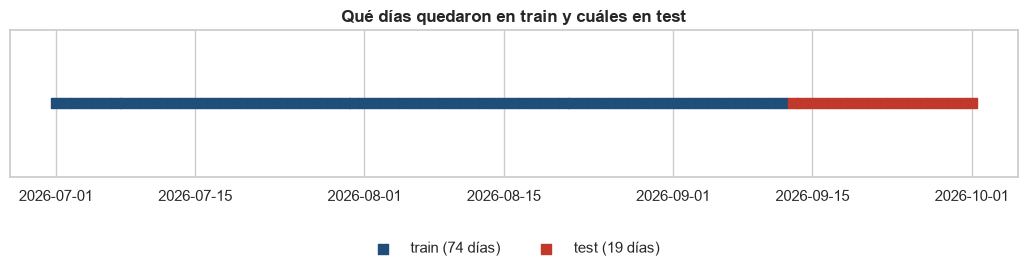

In [10]:
dia_de = consumo.index.normalize()
dias = np.sort(dia_de.unique())
dias_train, dias_test = train_test_split(dias, test_size=TEST_SIZE, shuffle=False)

train = consumo[dia_de.isin(dias_train)].copy()
test = consumo[dia_de.isin(dias_test)].copy()
print(f"Días totales: {len(dias)} | train: {len(dias_train)} | test: {len(dias_test)}")
print(f"Horas train: {len(train)} | horas test: {len(test)}")
print(f"Train: {pd.Timestamp(dias_train[0]):%Y-%m-%d} a {pd.Timestamp(dias_train[-1]):%Y-%m-%d}")
print(f"Test:  {pd.Timestamp(dias_test[0]):%Y-%m-%d} a {pd.Timestamp(dias_test[-1]):%Y-%m-%d}")

calendario = pd.DataFrame({"dia": pd.DatetimeIndex(dias)})
calendario["conjunto"] = np.where(calendario["dia"].isin(dias_test), "test", "train")
fig, ax = plt.subplots(figsize=(13, 1.9))
for conjunto in ["train", "test"]:
    parte = calendario[calendario["conjunto"] == conjunto]
    ax.scatter(
        parte["dia"],
        np.zeros(len(parte)),
        marker="s",
        s=60,
        color=COLORES[conjunto],
        label=f"{conjunto} ({len(parte)} días)",
    )
ax.set_yticks([])
ax.set_title("Qué días quedaron en train y cuáles en test")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=2, frameon=False)
plt.show()

**División train/test:**
> De los 93 días, los 74 más antiguos quedaron en **train** (1 de julio a 12 de septiembre,
> 1.757 horas) y los 19 más recientes en **test** (13 de septiembre a 1 de octubre, 450 horas).
> El 1 de julio es un día incompleto (solo 5 horas) y se excluye de los análisis diarios; el
> 1 de octubre, también incompleto, quedó en test.

## 5. Salud general

In [11]:
horas_por_dia = train.groupby(train.index.normalize()).size()
dias_completos = horas_por_dia[horas_por_dia == HORAS_DIA].index
dias_incompletos = horas_por_dia[horas_por_dia != HORAS_DIA]
print(f"Días en train: {len(horas_por_dia)} | completos (24 h): {len(dias_completos)}")
print("Días incompletos (fecha: horas):", dias_incompletos.to_dict())

resumen = pd.DataFrame(
    {
        "energia_total_mwh": train.sum() / 1000,
        "participacion_pct": train.sum() / train.sum().sum() * 100,
        "kwh_hora_mediana": train.median(),
        "kwh_hora_max": train.max(),
    }
)
display(resumen)

Días en train: 74 | completos (24 h): 73
Días incompletos (fecha: horas): {Timestamp('2026-07-01 00:00:00'): 5}


,energia_total_mwh,participacion_pct,kwh_hora_mediana,kwh_hora_max
R1,804.14,34.45,532.48,"1,439.74"
R2,832.67,35.67,516.10,"33,955.84"
R3,697.23,29.87,532.48,702.46


**Hallazgo: Los tres rectificadores no son iguales.**
> En train hay 73 días completos. R1 y R2 se reparten la energía casi por igual (35 % cada uno,
> ~800-830 MWh) y R3 consume algo menos (30 %, 697 MWh). La mediana por hora es parecida en los
> tres (516-532 kWh), pero el máximo de R1 (1.440 kWh) duplica al de R3 (702 kWh): R1 y R2
> trabajan con cargas mucho más variables que R3.

## 6. Valores faltantes (visibles y escondidos)

**Nota:** No hay celdas vacías, pero un contador puede quedarse quieto por dos razones muy distintas:

1. **Parada real:** el rectificador está apagado y no consume (un cero verdadero).
2. **Contador congelado:** el rectificador sí funciona, pero el SCADA deja de actualizar la
   lectura. Cuando vuelve la comunicación, el contador "salta" de golpe con toda la energía
   acumulada. Esas horas en cero son **datos faltantes disfrazados de cero**.

La forma de distinguirlos: un congelamiento termina con un salto imposible para una sola hora.

In [12]:
LIMITE_FISICO_FACTOR = 2

horas_cero = (train == 0).sum()
display(
    pd.DataFrame(
        {
            "vacios": train.isna().sum(),
            "horas_en_cero": horas_cero,
            "% horas en cero": horas_cero / len(train) * 100,
        }
    )
)

# Un salto es imposible si supera el doble del máximo que ese rectificador alcanza
# en una hora normal (percentil 99 de las horas en operación de train)
p99_operacion = train[train > UMBRAL_OPERACION_KWH].quantile(0.99)
limite_fisico = p99_operacion * LIMITE_FISICO_FACTOR
saltos = train.gt(limite_fisico)
print("Límite físico por hora (kWh):", limite_fisico.round(0).to_dict())
print("Horas con saltos imposibles:")
display(train[saltos.any(axis=1)])

,vacios,horas_en_cero,% horas en cero
R1,0,473,26.92
R2,0,528,30.05
R3,0,37,2.11


Límite físico por hora (kWh): {'R1': 2492.0, 'R2': 2473.0, 'R3': 1343.0}
Horas con saltos imposibles:


,R1,R2,R3
inicio,,,
2026-07-22 20:24:49.746,536.58,"33,955.84",546.82


In [13]:
def rachas_en_cero(serie: pd.Series) -> pd.DataFrame:
    """Encuentra las rachas de horas consecutivas con consumo cero.

    Args:
        serie: Consumo por hora de un rectificador (índice = inicio de la hora).

    Returns:
        Una fila por racha con su inicio, fin, duración en horas y el consumo de la hora
        siguiente (si existe en la serie).
    """
    es_cero = serie.eq(0)
    hueco = serie.index.to_series().diff().ne(pd.Timedelta(hours=1))
    grupo = (es_cero.ne(es_cero.shift()) | hueco).cumsum()
    filas = []
    for _, bloque in serie[es_cero].groupby(grupo[es_cero]):
        siguiente = bloque.index[-1] + pd.Timedelta(hours=1)
        filas.append(
            {
                "inicio": bloque.index[0],
                "fin": bloque.index[-1],
                "horas": len(bloque),
                "kwh_hora_siguiente": serie.get(siguiente, np.nan),
            }
        )
    return pd.DataFrame(filas)


rachas = pd.concat(
    [rachas_en_cero(train[r]).assign(rectificador=r) for r in RECT], ignore_index=True
)
rachas["dia_semana"] = rachas["inicio"].dt.dayofweek.map(dict(enumerate(DIAS_SEMANA)))
rachas["tipo"] = np.where(
    rachas["kwh_hora_siguiente"] > rachas["rectificador"].map(limite_fisico),
    "contador congelado",
    "parada real",
)
display(
    rachas.groupby(["rectificador", "tipo"])["horas"].agg(
        rachas="size", horas="sum", racha_mas_larga="max"
    )
)
print("Día de la semana en que empiezan las rachas de parada:")
display(
    pd.crosstab(rachas["rectificador"], rachas["dia_semana"]).reindex(
        columns=DIAS_SEMANA, fill_value=0
    )
)
display(rachas[rachas["tipo"] == "contador congelado"])

rachas  horas  racha_mas_larga
rectificador tipo                                              
R1           parada real             19    473               66
R2           contador congelado       1     96               96
             parada real             20    432               66
R3           parada real              3     37               27

Día de la semana en que empiezan las rachas de parada:


dia_semana,Lun,Mar,Mié,Jue,Vie,Sáb,Dom
rectificador,,,,,,,
R1,1,2,2,1,1,11,1
R2,2,2,2,1,1,11,2
R3,1,0,0,0,0,1,1


,inicio,fin,horas,kwh_hora_siguiente,rectificador,dia_semana,tipo
24,2026-07-18 20:24:49.746,2026-07-22 19:24:49.746,96,"33,955.84",R2,Sáb,contador congelado


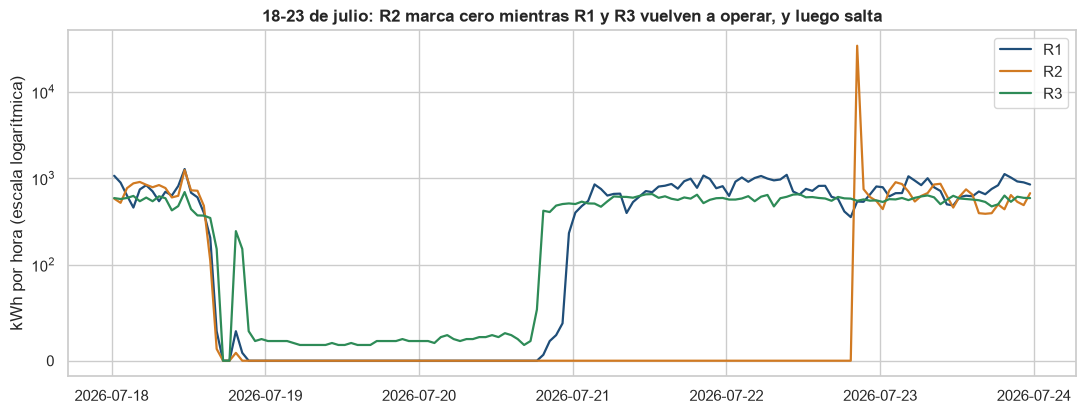

In [14]:
ventana = train.loc["2026-07-18":"2026-07-23"]
fig, ax = plt.subplots(figsize=(13, 4.5))
for rect in RECT:
    ax.plot(ventana.index, ventana[rect], color=COLORES[rect], lw=1.6, label=rect)
ax.set_yscale("symlog", linthresh=100)
ax.set_title("18-23 de julio: R2 marca cero mientras R1 y R3 vuelven a operar, y luego salta")
ax.set_ylabel("kWh por hora (escala logarítmica)")
ax.legend()
plt.show()

**Hallazgo: Hay un faltante escondido en R2 entre el 18 y el 22 de julio.**
> - No hay celdas vacías, pero R1 está en cero el 27 % de las horas, R2 el 30 % y R3 solo el 2 %.
> - El contador de R2 no se movió durante **96 horas** (del sábado 18 de julio a las 8:24 p. m.
>   al miércoles 22 a las 7:24 p. m.) y en la hora siguiente **saltó 33.956 kWh**, unas 50 veces
>   lo normal.
> - El gráfico muestra qué pasó: del sábado al lunes en la tarde los tres rectificadores
>   estaban apagados (una parada real de fin de semana largo). El lunes 20 en la noche R1 y R3
>   volvieron a operar, pero R2 siguió marcando cero hasta el miércoles. Esas ~48 horas a unos
>   700 kWh por hora dan justo el salto. Conclusión: **R2 sí estuvo funcionando desde el lunes en
>   la noche; lo que falló fue la comunicación con el SCADA**. Esas horas en cero son datos
>   faltantes, no una parada.
> - Las demás rachas en cero (19 en R1, 20 en R2, 3 en R3) sí parecen **paradas reales**: la
>   mayoría empieza un sábado y las más largas duran ~66 horas (sábado en la tarde hasta lunes),
>   es decir, el fin de semana.

## 7. Evolución temporal y patrones

### 7.1 Consumo diario

**Nota:** Para no deformar los patrones con el salto del contador, en esta sección el salto se reparte
entre las horas en que el contador estuvo congelado **siguiendo el perfil de los otros dos
rectificadores**: si ellos estaban apagados (por ejemplo, el domingo), a esa hora no se le asigna
energía. La energía total se conserva. Esto se hace sobre una copia (`train_corr`) y se documenta
en la sección 11.

Energía total antes y después de repartir el salto (MWh):
    antes  despues
R1 804.14   804.14
R2 832.67   832.67
R3 697.23   697.23


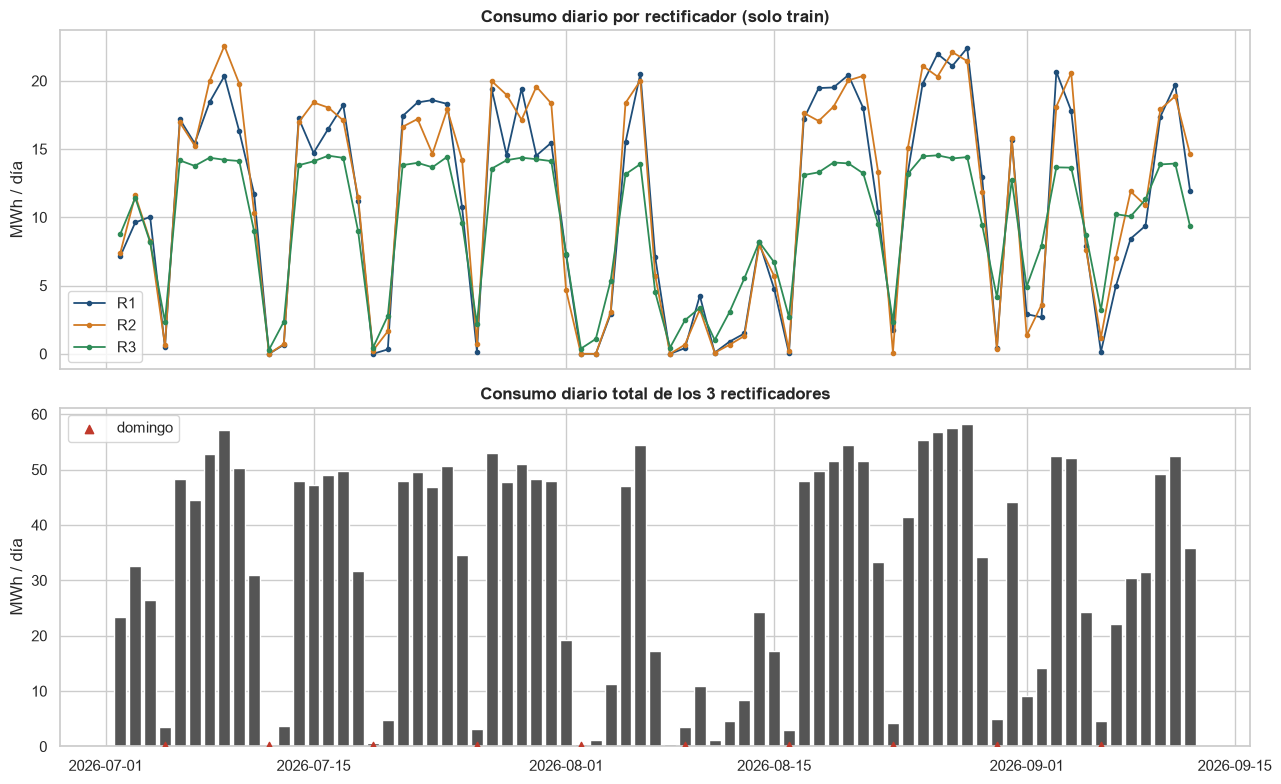

In [15]:
train_corr = train.copy()
for _, racha in rachas[rachas["tipo"] == "contador congelado"].iterrows():
    rect = racha["rectificador"]
    horas = pd.date_range(racha["inicio"], racha["fin"] + pd.Timedelta(hours=1), freq="h")
    energia = train_corr.loc[horas, rect].sum()
    pesos = train.loc[horas, [r for r in RECT if r != rect]].mean(axis=1)
    train_corr.loc[horas, rect] = energia * pesos / pesos.sum()
print("Energía total antes y después de repartir el salto (MWh):")
print(pd.DataFrame({"antes": train.sum() / 1000, "despues": train_corr.sum() / 1000}).round(2))

diario = train_corr.groupby(train_corr.index.normalize()).sum().loc[dias_completos]
diario["Total"] = diario[RECT].sum(axis=1)
diario_cal = diario.reindex(pd.date_range(diario.index.min(), diario.index.max(), freq="D"))

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for rect in RECT:
    axes[0].plot(
        diario_cal.index,
        diario_cal[rect] / 1000,
        marker="o",
        ms=3,
        lw=1.3,
        color=COLORES[rect],
        label=rect,
    )
axes[0].set_title("Consumo diario por rectificador (solo train)")
axes[0].set_ylabel("MWh / día")
axes[0].legend(loc="lower left")
axes[1].bar(diario_cal.index, diario_cal["Total"] / 1000, color=COLORES["Total"])
domingos = diario.index[diario.index.dayofweek == DOMINGO]
axes[1].scatter(
    domingos,
    np.zeros(len(domingos)),
    marker="^",
    color=COLORES["atipico"],
    label="domingo",
    zorder=3,
)
axes[1].set_title("Consumo diario total de los 3 rectificadores")
axes[1].set_ylabel("MWh / día")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Hallazgo: El consumo sigue un ciclo semanal muy marcado.**
> - Un día laboral normal consume entre **45 y 58 MWh** entre los tres rectificadores; los
>   domingos (triángulos rojos) el consumo cae prácticamente a cero.
> - En la **primera mitad de agosto** hay muchos días con muy poco consumo (por debajo de
>   25 MWh), lo que sugiere una operación reducida o una parada programada (mantenimiento,
>   vacaciones colectivas o baja demanda).
> - La semana del 18 de julio también tuvo una parada larga: del sábado al lunes en la tarde.
> - R1 y R2 se mueven casi siempre juntos; R3 es más estable y rara vez baja a cero.

### 7.2 Patrón semanal

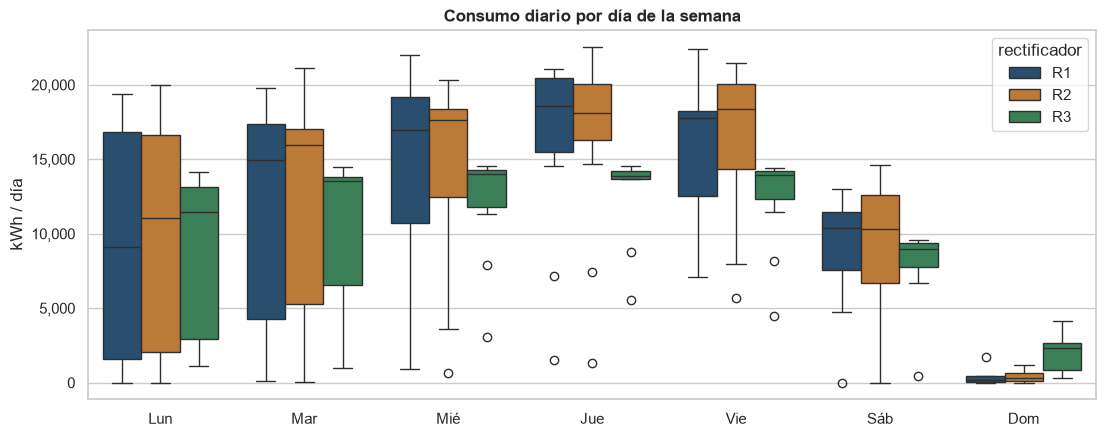

MWh mediano por día,R1,R2,R3
dia_semana,,,
Lun,9.10,11.00,11.50
Mar,15.00,15.90,13.50
Mié,17.00,17.70,14.00
Jue,18.60,18.10,13.90
Vie,17.80,18.30,13.90
Sáb,10.40,10.40,9.00
Dom,0.10,0.30,2.40


In [16]:
diario_largo = (
    diario[RECT]
    .reset_index(names="dia")
    .melt(id_vars="dia", var_name="rectificador", value_name="kwh")
)
diario_largo["dia_semana"] = pd.Categorical(
    diario_largo["dia"].dt.dayofweek.map(dict(enumerate(DIAS_SEMANA))),
    categories=DIAS_SEMANA,
    ordered=True,
)
fig, ax = plt.subplots(figsize=(13, 4.8))
sns.boxplot(data=diario_largo, x="dia_semana", y="kwh", hue="rectificador", palette=COLORES, ax=ax)
ax.set_title("Consumo diario por día de la semana")
ax.set_xlabel("")
ax.set_ylabel("kWh / día")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
plt.show()

semana = diario_largo.pivot_table(
    index="dia_semana", columns="rectificador", values="kwh", aggfunc="median", observed=False
)
display((semana / 1000).round(1).rename_axis(columns="MWh mediano por día"))

**Hallazgo: Jueves y viernes son los días de mayor consumo; el domingo casi no hay operación.**
> - R1 y R2 consumen unos 18 MWh diarios los jueves y viernes, unos 10 MWh los sábados y apenas
>   0.1-0.5 MWh los domingos.
> - El **lunes** es más bajo de lo esperado (mediana de 9-12 MWh en R1 y R2): la planta arranca
>   el domingo en la noche, pero hay lunes en que la operación empieza tarde o sigue parada.
> - R3 es el más constante: unos 13.5-14 MWh de martes a viernes, ~9 MWh el sábado y ~2.4 MWh el
>   domingo (es el único que mantiene algo de carga el fin de semana).
> - Para un modelo, **el tipo de día (laboral, sábado, domingo, parada)** es la variable más
>   importante para explicar el consumo diario.

### 7.3 Patrón por hora del día

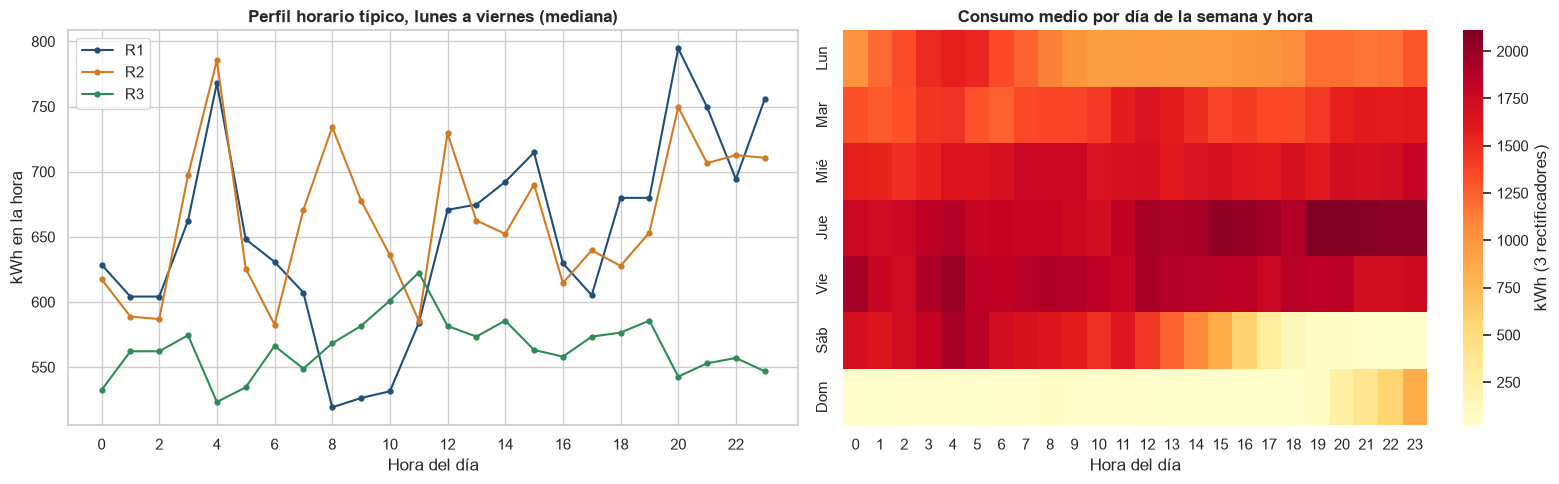

In [17]:
por_hora = train_corr.assign(
    hora=train_corr.index.hour,
    dia_semana=pd.Categorical(
        train_corr.index.dayofweek.map(dict(enumerate(DIAS_SEMANA))),
        categories=DIAS_SEMANA,
        ordered=True,
    ),
)
por_hora["Total"] = por_hora[RECT].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
laborales = por_hora[por_hora.index.dayofweek < SABADO]
perfil = laborales.groupby("hora")[RECT].median()
for rect in RECT:
    axes[0].plot(perfil.index, perfil[rect], marker="o", ms=3.5, color=COLORES[rect], label=rect)
axes[0].set_title("Perfil horario típico, lunes a viernes (mediana)")
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("kWh en la hora")
axes[0].set_xticks(range(0, HORAS_DIA, 2))
axes[0].legend()

mapa = por_hora.pivot_table(
    index="dia_semana", columns="hora", values="Total", aggfunc="mean", observed=False
)
sns.heatmap(mapa, cmap="YlOrRd", ax=axes[1], cbar_kws={"label": "kWh (3 rectificadores)"})
axes[1].set_title("Consumo medio por día de la semana y hora")
axes[1].set_xlabel("Hora del día")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Hallazgo: Entre semana la formación trabaja 24 horas sin un patrón horario fuerte.**
> - De lunes a viernes no hay horas "pico" claras: R1 y R2 oscilan entre ~520 y ~800 kWh por
>   hora sin un ciclo repetitivo, y R3 se mantiene plano entre 520 y 620 kWh. Esto es coherente
>   con un proceso continuo (las baterías se cargan durante muchas horas seguidas).
> - El mapa de calor muestra el **ciclo de fin de semana**: el sábado desde la 1-2 p. m. el
>   consumo empieza a bajar y hacia el final de la tarde queda casi en cero, el domingo está
>   apagado y hacia las 7-8 p. m. del domingo vuelve a arrancar. El lunes en el día el consumo
>   todavía es más bajo que el resto de la semana.

**Algo que se podría tomar en cuenta**
> Los reportes diarios deberían comparar cada día contra días del mismo tipo (un domingo contra
> domingos), no contra el promedio general.

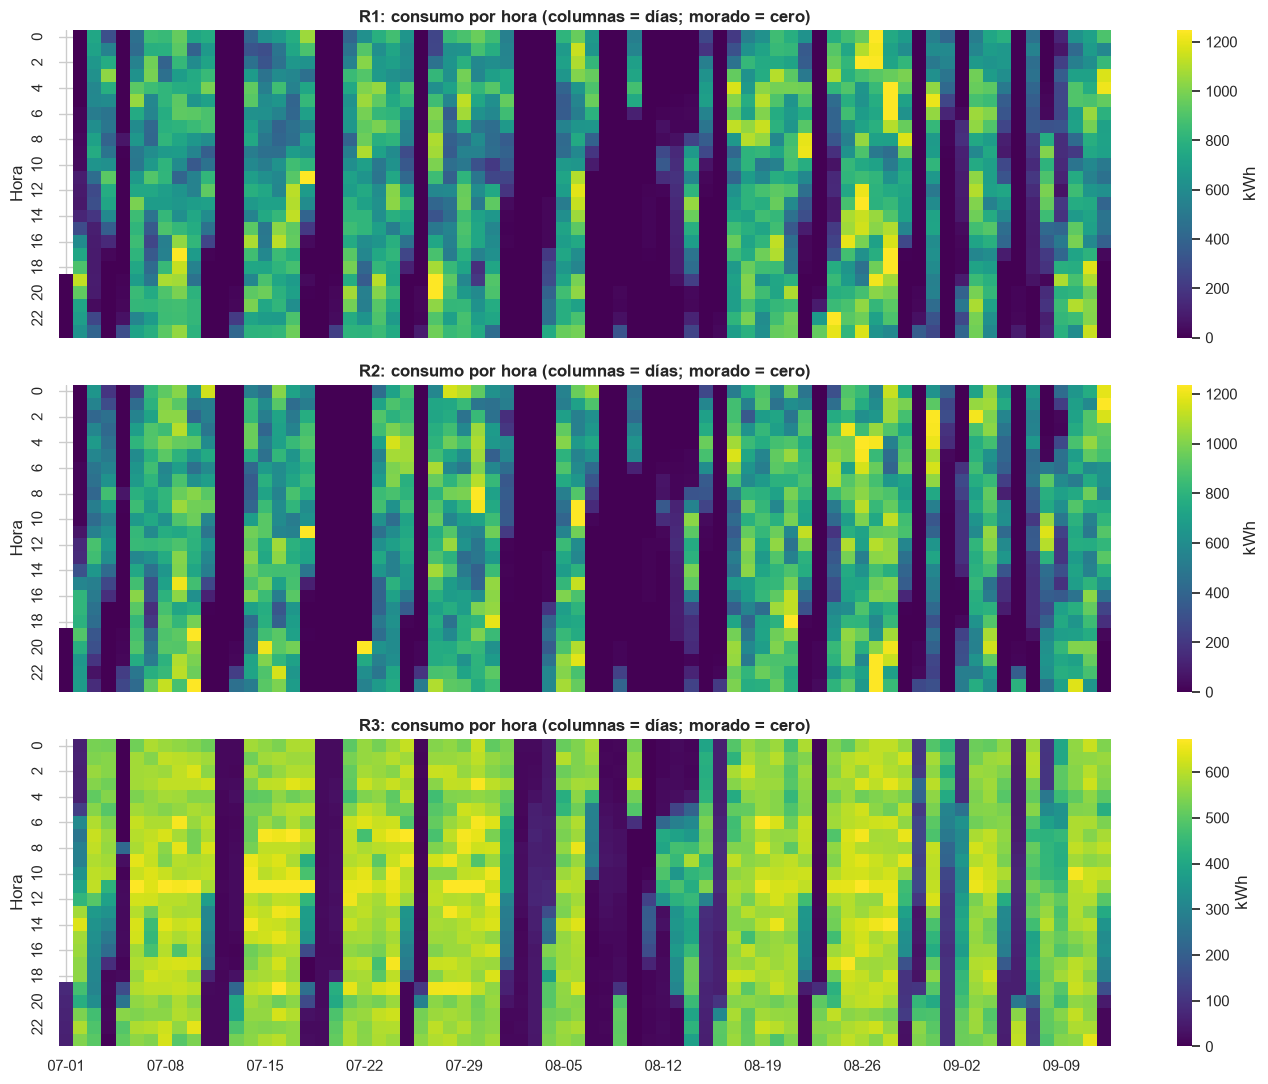

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
calendario_horas = pd.date_range(train.index.min(), train.index.max(), freq="h")
for ax, rect in zip(axes, RECT, strict=True):
    serie = train[rect].reindex(calendario_horas)
    tabla = serie.groupby([serie.index.normalize(), serie.index.hour]).first().unstack()
    sns.heatmap(
        tabla.T,
        cmap="viridis",
        ax=ax,
        vmin=0,
        vmax=float(p99_operacion[rect]),
        cbar_kws={"label": "kWh"},
    )
    ax.set_title(f"{rect}: consumo por hora (columnas = días; morado = cero)")
    ax.set_ylabel("Hora")
    etiquetas = [pd.Timestamp(d).strftime("%m-%d") for d in tabla.index]
    ax.set_xticks(np.arange(len(etiquetas))[::7] + 0.5, etiquetas[::7], rotation=0)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Hallazgo: El mapa hora por hora deja ver las paradas y el problema de R2.**
> Cada columna es un día y cada fila una hora; el morado oscuro es consumo cero. Se distinguen
> las franjas de cada fin de semana en los tres rectificadores, el bloque de R2 en cero hasta el
> 22 de julio mientras R1 y R3 ya operaban (el contador congelado) y la primera mitad de agosto,
> con R1 y R2 apagados varios días seguidos y R3 a carga baja.

### 7.4 Evolución por mes y tendencia

**Nota:** Como cada mes tiene distinto número de días en train, se compara el consumo promedio
por día de cada mes, no el total.

In [19]:
por_mes = diario.groupby(diario.index.to_period("M")).agg(["mean", "size"])
promedio_mes = por_mes.xs("mean", axis=1, level=1) / 1000
promedio_mes["dias_en_train"] = por_mes[("Total", "size")]
display(promedio_mes.round(2).rename_axis(columns="MWh promedio por día"))

paradas_mes = (
    rachas[rachas["tipo"] == "parada real"]
    .assign(mes=lambda d: d["inicio"].dt.to_period("M"))
    .pivot_table(index="mes", columns="rectificador", values="horas", aggfunc="sum")
)
print("Horas de parada real por mes (train):")
display(paradas_mes)

dias_num = (diario.index - diario.index.min()).days
for columna in [*RECT, "Total"]:
    rho, p_valor = stats.spearmanr(dias_num, diario[columna])
    veredicto = "tendencia clara" if p_valor < ALPHA else "sin tendencia clara"
    print(f"{columna}: rho = {rho:+.2f}, p = {p_valor:.3f} -> {veredicto}")

MWh promedio por día,R1,R2,R3,Total,dias_en_train
inicio,,,,,
2026-07,12.42,13.09,10.67,36.18,30
2026-08,9.93,9.88,8.25,28.06,31
2026-09,10.32,11.14,10.07,31.53,12


Horas de parada real por mes (train):


rectificador,R1,R2,R3
mes,,,
2026-07,154.00,108.00,10.00
2026-08,269.00,268.00,27.00
2026-09,50.00,56.00,NaN


R1: rho = +0.06, p = 0.619 -> sin tendencia clara
R2: rho = +0.04, p = 0.708 -> sin tendencia clara
R3: rho = -0.04, p = 0.730 -> sin tendencia clara
Total: rho = +0.06, p = 0.588 -> sin tendencia clara


**Hallazgo: Agosto fue un mes atípico y el periodo es muy corto para ver tendencias.**
> - El consumo promedio por día fue de 36.2 MWh en julio, 28.1 en agosto y 31.5 en los 12 días
>   de septiembre que están en train: agosto consumió cerca de un 22 % menos que julio.
> - La razón son las paradas: R1 y R2 estuvieron detenidos unas 270 horas en agosto, frente a
>   108-154 horas en julio.
> - La prueba de tendencia no detecta crecimiento ni caída en el periodo (p > 0.5). Con menos de
>   tres meses en train no se puede hablar de estacionalidad; para eso hace falta más historia
>   del SCADA.

## 8. Distribuciones y valores atípicos

### 8.1 Consumo por hora

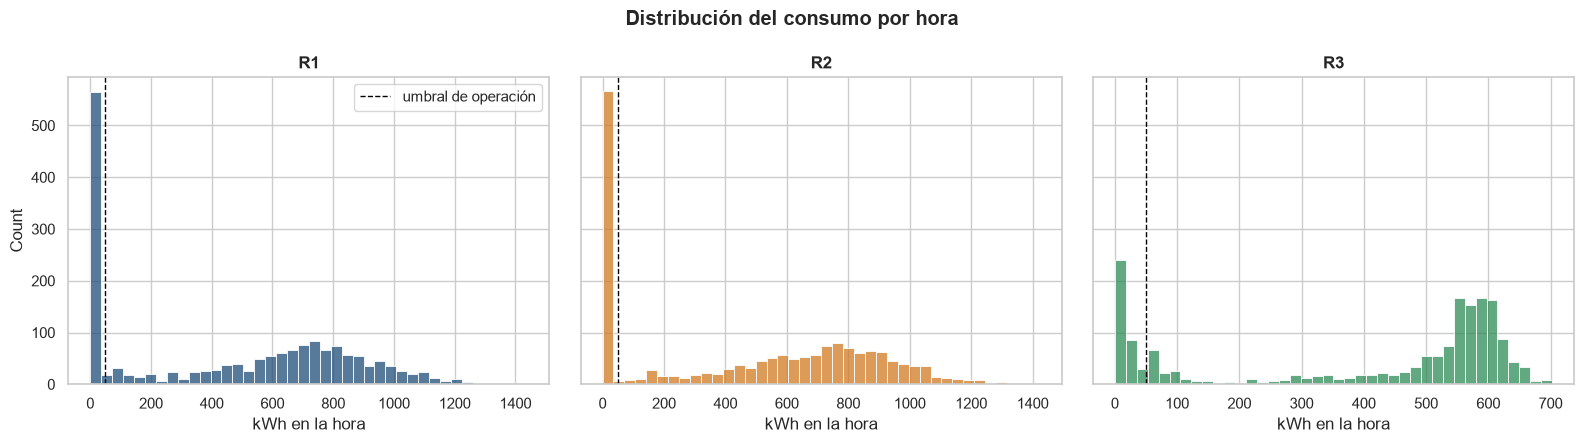

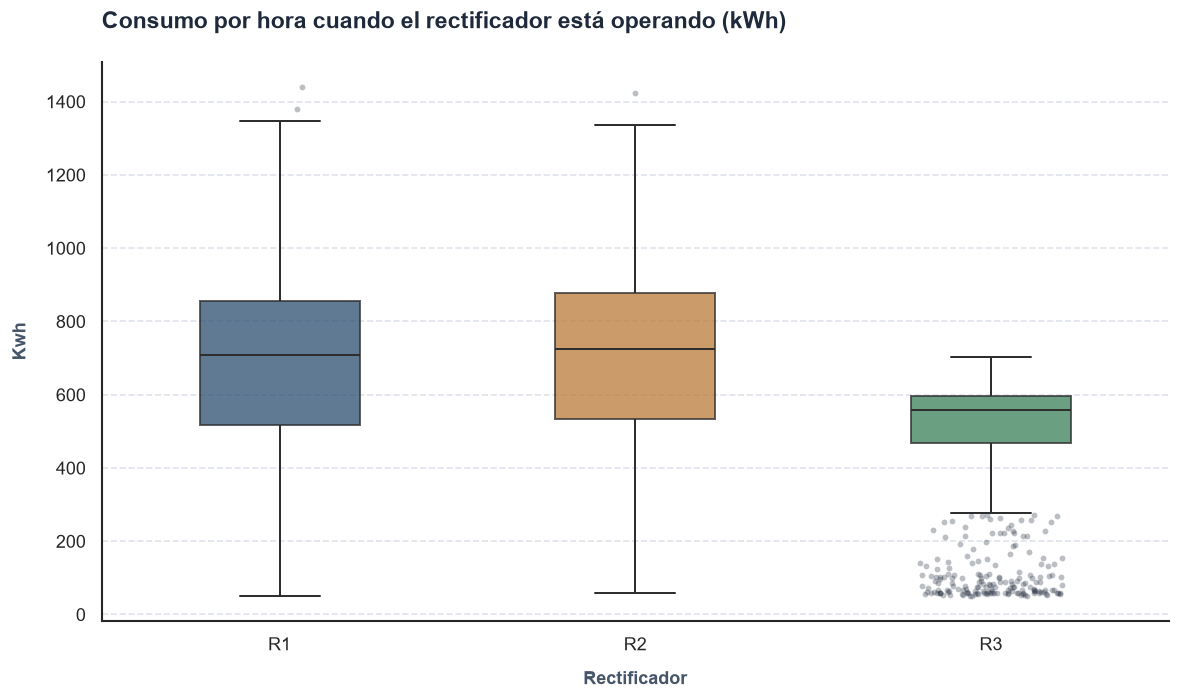

,count,mean,std,min,25%,50%,75%,max
rectificador,,,,,,,,
R1,"1,186.00",676.64,269.70,51.20,516.10,708.61,855.55,"1,439.74"
R2,"1,191.00",697.67,258.11,57.34,534.53,724.99,878.59,"1,423.36"
R3,"1,405.00",492.30,165.78,51.20,466.94,557.06,595.97,702.46


In [20]:
horario_largo = train_corr.reset_index().melt(
    id_vars="inicio", var_name="rectificador", value_name="kwh"
)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, rect in zip(axes, RECT, strict=True):
    sns.histplot(train_corr[rect], bins=40, color=COLORES[rect], ax=ax)
    ax.axvline(UMBRAL_OPERACION_KWH, color="black", ls="--", lw=1, label="umbral de operación")
    ax.set_title(rect)
    ax.set_xlabel("kWh en la hora")
axes[0].legend()
plt.suptitle("Distribución del consumo por hora", fontweight="bold")
plt.tight_layout()
plt.show()

operacion = horario_largo[horario_largo["kwh"] > UMBRAL_OPERACION_KWH]
plot_segmented_boxplot(
    operacion,
    num_col="kwh",
    cat_col="rectificador",
    palette=[COLORES[r] for r in RECT],
    title="Consumo por hora cuando el rectificador está operando (kWh)",
    x_rotation=0,
)
aplicar_estilo()
display(operacion.groupby("rectificador")["kwh"].describe())

**Hallazgo: Hay dos "modos" de funcionamiento y un R3 muy distinto.**
> - Los histogramas tienen dos grupos: un pico grande en cero (apagado) y una "loma" de horas en
>   operación. Por eso cualquier promedio que mezcle ambos grupos describe mal el comportamiento
>   real.
> - Cuando operan, **R1 y R2** consumen en promedio unos 680-700 kWh por hora, con un rango muy
>   amplio (de 50 a más de 1.400 kWh): su carga depende del programa de carga de las baterías.
> - **R3** se concentra entre 470 y 600 kWh (mediana 557) y nunca pasa de 702: trabaja a una
>   carga casi constante, o es un equipo de menor capacidad.

### 8.2 Consumo diario total

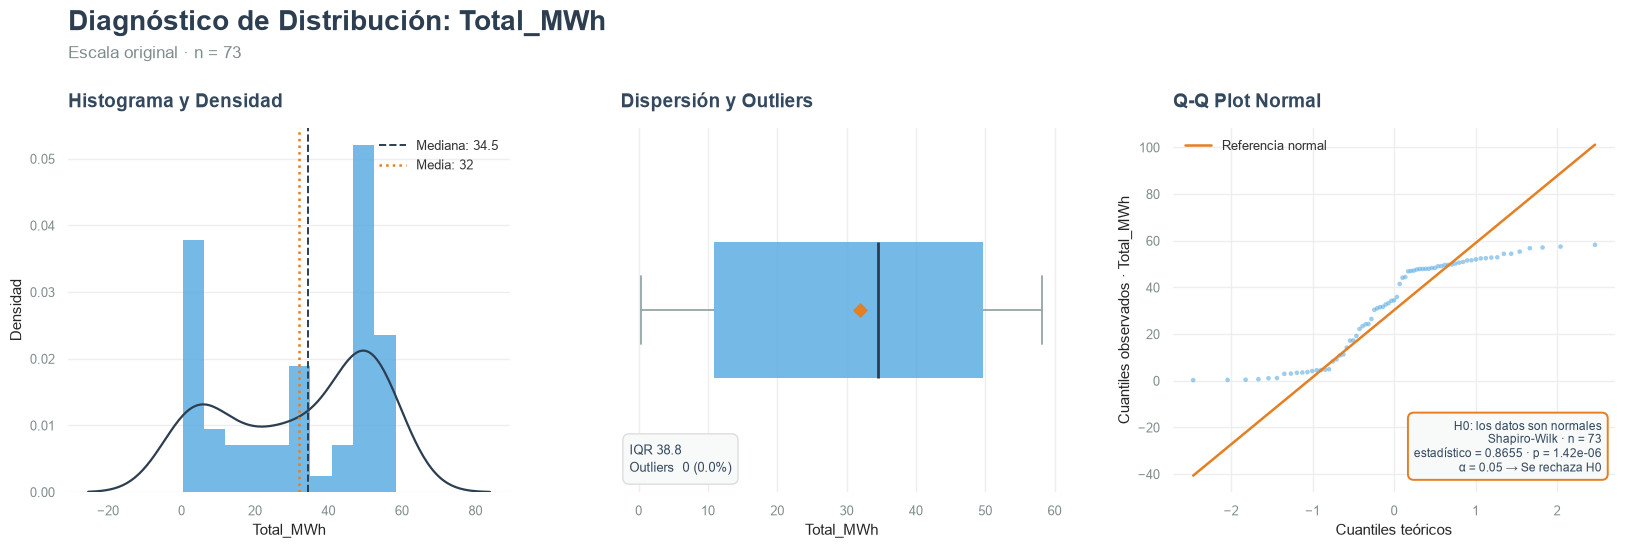

{'n': 73, 'mean': 31.96852252054795, 'median': 34.484224000000005, 'skew': -0.3684572473779635, 'p_value': 1.4219334720151043e-06, 'is_normal': False}


In [21]:
resultado = normality_report(
    diario.reset_index(drop=True).assign(Total_MWh=lambda d: d["Total"] / 1000),
    "Total_MWh",
    random_state=RANDOM_STATE,
)
aplicar_estilo()
print({k: resultado.get(k) for k in ["n", "mean", "median", "skew", "p_value", "is_normal"]})

**Hallazgo: El consumo diario tampoco es "normal", hay dos tipos de día.**
> La prueba de normalidad lo rechaza con claridad (p < 0.001). El histograma muestra un grupo de
> días de operación plena (~45-58 MWh) y otro de días de fin de semana o parada (0-20 MWh). La
> media (32.0 MWh) queda en medio de los dos grupos y no representa ningún día real; un modelo
> debe tratar estos regímenes por separado.

### 8.3 Valores atípicos

Se aplica la regla del rango intercuartílico (IQR) a las horas de operación de cada
rectificador, más la regla física de la sección 6 (saltos imposibles).

In [22]:
FACTOR_IQR = 1.5

filas = []
for rect in RECT:
    valores = train[rect][train[rect] > UMBRAL_OPERACION_KWH]
    q1, q3 = valores.quantile([0.25, 0.75])
    ancho_caja = q3 - q1
    limite_inf, limite_sup = q1 - FACTOR_IQR * ancho_caja, q3 + FACTOR_IQR * ancho_caja
    atipicos = valores[(valores < limite_inf) | (valores > limite_sup)]
    filas.append(
        {
            "rectificador": rect,
            "horas_operando": len(valores),
            "limite_inferior": limite_inf,
            "limite_superior": limite_sup,
            "atipicos_bajos": int((atipicos < limite_inf).sum()),
            "atipicos_altos": int((atipicos > limite_sup).sum()),
            "saltos_imposibles": int(saltos[rect].sum()),
        }
    )
display(pd.DataFrame(filas).set_index("rectificador"))

,horas_operando,limite_inferior,limite_superior,atipicos_bajos,atipicos_altos,saltos_imposibles
rectificador,,,,,,
R1,1186,6.91,"1,364.74",0,2,0
R2,1141,1.02,"1,418.24",0,2,1
R3,1405,273.41,789.50,175,0,0


**Hallazgo: Casi todos los "atípicos" son comportamiento normal; solo hay un error de datos.**
> - R1 y R2 tienen 2 horas cada uno por encima del límite superior (~1.365-1.418 kWh): picos de
>   carga altos pero posibles.
> - R3 tiene 175 horas "atípicas" por abajo (menos de ~273 kWh). No son errores: R3 es tan estable
>   que cualquier hora a carga parcial (fines de semana, arranques) queda fuera de su caja.
> - El único error de datos es el salto imposible de R2 del 22 de julio.

## 9. Comparación entre rectificadores

,% horas operando,potencia_media_operando_kw,participacion_energia_pct
R1,67.50,676.64,34.45
R2,67.79,697.67,35.67
R3,79.97,492.30,29.87


Horas según cuántos rectificadores están operando a la vez:
0   20.00
1   11.40
2    1.90
3   66.70


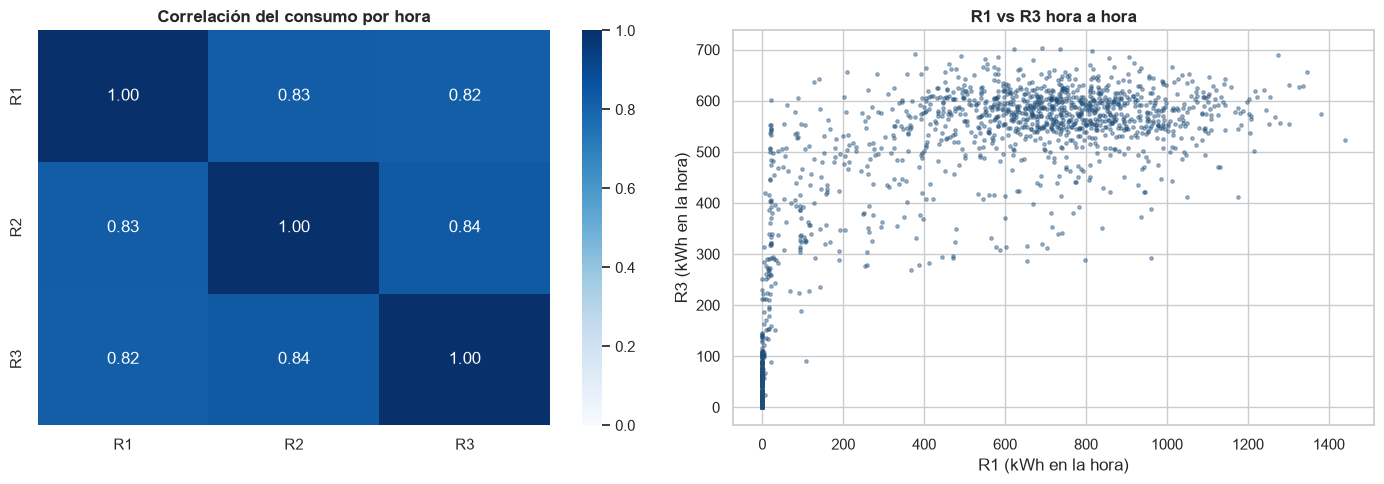

In [23]:
operando = train_corr > UMBRAL_OPERACION_KWH
uso = pd.DataFrame(
    {
        "% horas operando": operando.mean() * 100,
        "potencia_media_operando_kw": train_corr[operando].mean(),
        "participacion_energia_pct": train_corr.sum() / train_corr.sum().sum() * 100,
    }
)
display(uso)

cuantos = operando.sum(axis=1).value_counts().sort_index()
print("Horas según cuántos rectificadores están operando a la vez:")
print((cuantos / len(operando) * 100).round(1).rename("% de horas").to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(train_corr.corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Correlación del consumo por hora")
axes[1].scatter(train_corr["R1"], train_corr["R3"], s=6, alpha=0.4, color=COLORES["R1"])
axes[1].set_xlabel("R1 (kWh en la hora)")
axes[1].set_ylabel("R3 (kWh en la hora)")
axes[1].set_title("R1 vs R3 hora a hora")
plt.tight_layout()
plt.show()

**Hallazgo: Los tres rectificadores trabajan casi siempre juntos.**
> - R1 y R2 operan el 68 % de las horas con una potencia media de unos 680-700 kW; R3 opera el
>   80 % a unos 490 kW.
> - El 67 % de las horas los tres están operando a la vez y el 20 % están los tres apagados
>   (sobre todo fines de semana). Solo un 13 % del tiempo opera uno o dos.
> - La correlación hora a hora es alta (0.82-0.84) una vez corregido el salto de R2. El gráfico
>   R1 vs R3 muestra que, cuando R1 está encendido, R3 se queda en ~550-600 kWh sin importar
>   cuánto consuma R1: R3 aporta una carga estable y R1 (igual que R2) la parte variable.

## 10. Validación cruzada con el consumo mensual de F&A

El archivo de F&A (primer notebook) tiene el consumo de **julio de 2026**, el único mes en que
coinciden ambas fuentes. Se estima el consumo de julio de los rectificadores con los días
completos de julio que están en train y se compara con:

- el **consumo total de F&A** en julio, y
- la parte que el Excel le **asigna a Formación** (85 % del total).

**Cuidado con el promedio simple.** Multiplicar el promedio diario por 31 sobreestima julio si
en train quedaron menos domingos (que casi no consumen) de los que tiene el mes. Por eso cada
día de julio se estima con el promedio de **su mismo día de la semana**.

Domingos de julio en train: 4 de 4
Estimación simple (promedio x 31): 1,121.6 MWh
Días completos de julio en train: 30


,MWh en julio 2026
F&A total (Excel),"1,144.70"
Formación asignada 85 % (Excel),973.00
"Rectificadores R1+R2+R3 (SCADA, estimado)","1,135.60"


Los rectificadores equivalen al 99.2% del consumo total F&A


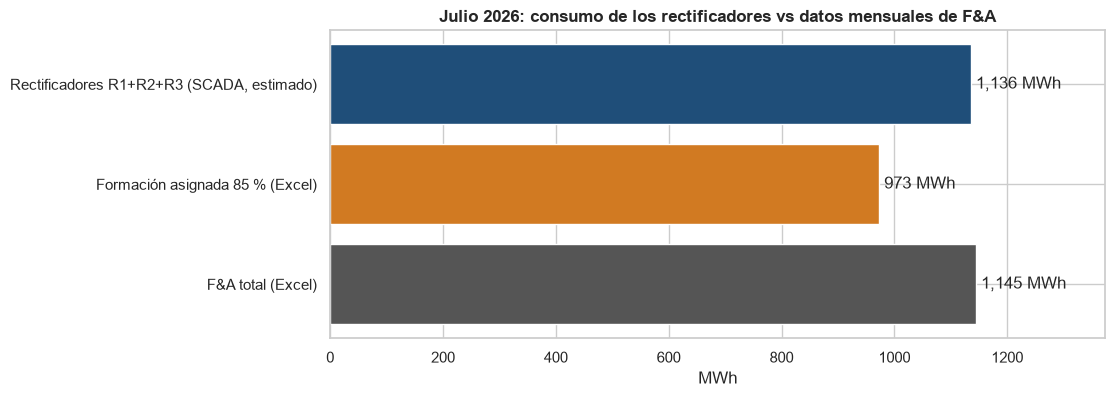

In [24]:
fa = pd.read_excel(FA_PATH, sheet_name="F&A", header=None)
fa = fa.iloc[2:, 1:].set_axis([" ".join(str(c).split()) for c in fa.iloc[1, 1:]], axis=1)
ANIO_CRUCE, MES_CRUCE, DIAS_JULIO = 2026, 7, 31
PARTICIPACION_FORMACION = 0.85
fila_julio = fa[(fa["Año"] == ANIO_CRUCE) & (fa["Mes"] == "Jul") & (fa["Proceso"] == "F&A")]
kwh_fa_julio = float(fila_julio["KWH"].iloc[0])

julio = diario[(diario.index.year == ANIO_CRUCE) & (diario.index.month == MES_CRUCE)]
dias_de_julio = pd.date_range(f"{ANIO_CRUCE}-{MES_CRUCE:02d}-01", periods=DIAS_JULIO, freq="D")
promedio_dia_semana = julio.groupby(julio.index.dayofweek)["Total"].mean()
estimado_julio = float(dias_de_julio.to_series().dt.dayofweek.map(promedio_dia_semana).sum())
estimado_simple = julio["Total"].mean() * DIAS_JULIO
print(
    "Domingos de julio en train:",
    int((julio.index.dayofweek == DOMINGO).sum()),
    "de",
    int((dias_de_julio.dayofweek == DOMINGO).sum()),
)
print(f"Estimación simple (promedio x 31): {estimado_simple / 1000:,.1f} MWh")
comparacion = (
    pd.Series(
        {
            "F&A total (Excel)": kwh_fa_julio,
            "Formación asignada 85 % (Excel)": kwh_fa_julio * PARTICIPACION_FORMACION,
            "Rectificadores R1+R2+R3 (SCADA, estimado)": estimado_julio,
        }
    )
    / 1000
)
print(f"Días completos de julio en train: {len(julio)}")
display(comparacion.round(1).rename("MWh en julio 2026").to_frame())
print(f"Los rectificadores equivalen al {estimado_julio / kwh_fa_julio:.1%} del consumo total F&A")

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(
    comparacion.index, comparacion.to_numpy(), color=[COLORES["Total"], "#d17a22", COLORES["R1"]]
)
for y, valor in enumerate(comparacion.to_numpy()):
    ax.text(valor, y, f" {valor:,.0f} MWh", va="center")
ax.set_xlim(0, comparacion.max() * 1.2)
ax.set_title("Julio 2026: consumo de los rectificadores vs datos mensuales de F&A")
ax.set_xlabel("MWh")
plt.show()

**Hallazgo: Los rectificadores consumen casi todo lo que consume F&A.**
> - Primero, esto **confirma la unidad**: si las lecturas no estuvieran en Wh, la comparación
>   saldría 1.000 veces fuera de escala.
> - Todo julio está en train (30 días completos, con sus 4 domingos). Los tres rectificadores
>   consumieron aproximadamente **1.136 MWh**, frente a **1.145 MWh** de todo F&A: cerca del
>   **99 %**. El Excel le asigna a Formación solo el 85 % (973 MWh), es decir, subestima a
>   Formación en unos 160 MWh al mes. La estimación simple (promedio x 31) da casi lo mismo
>   (1.122 MWh), porque julio está completo.
> - Si los rectificadores son solo una parte de Formación, el reparto 85/15 del Excel no puede
>   ser correcto: a la Línea de Acabado (y a los demás equipos de Formación) les quedaría muy
>   poco. Otra posibilidad es que el medidor de F&A no incluya todo lo que miden los
>   rectificadores.
> - Ojo: julio de 2026 está en el conjunto de **test del EDA de F&A**. Aquí ese valor se usa solo
>   como referencia de unidades y de magnitud, no para tomar decisiones del modelo de F&A.

## 11. Estrategia de valores faltantes

| Situación | Qué tipo de faltante es | Qué hacer (propuesta) |
|---|---|---|
| Contador congelado + salto (R2, 18-22 jul) | Faltante disfrazado de cero (falla de comunicación con el SCADA), mezclado con una parada real de fin de semana. | Marcar las horas como faltantes. Para totales diarios/mensuales, **repartir el salto** entre las horas congeladas siguiendo el perfil de los otros rectificadores (así se hizo en este EDA; la energía total se conserva). |
| Rachas en cero sin salto (fines de semana, paradas) | **Ceros reales**: el equipo estaba apagado. | Conservarlas como cero. Agregar una variable de "tipo de día" (laboral, sábado, domingo, parada) para que el modelo las entienda. |
| Días incompletos (1 jul en train, 1 oct en test) | Faltan horas al inicio y al final del archivo. | Excluirlos de los análisis diarios, o completarlos solo cuando llegue la siguiente descarga del SCADA. **No imputar.** |
| Lecturas en el minuto 24:49 | No es un faltante, es un desfase de la rejilla horaria. | En la ingesta, asignar cada intervalo a su hora de inicio (o interpolar a la hora en punto) y convertir a UTC. |
| Resolución de 2 kWh | Precisión limitada del SCADA. | No requiere tratamiento; documentarlo para no confundir valores pequeños con errores. |
| Detección automática futura | - | Regla para la plataforma: una hora con consumo **mayor al doble del máximo normal** del equipo, precedida de horas en cero, se marca como "contador congelado". El umbral se calcula **solo con train**. |

**Regla general para la siguiente iteración:** las decisiones de imputación se toman con el
modelo, cualquier cálculo para llenar huecos se ajusta **solo con train**, y un faltante
**nunca** se reemplaza por cero (regla del proyecto).

## 12. Conclusiones

**Conclusiones del EDA de rectificadores (con los datos de train, 1 de julio a 12 de septiembre)**
> 1. **Los datos son muy limpios en su estructura:** una lectura por hora sin huecos ni
>    repetidos, y contadores que nunca retroceden. Las lecturas están en Wh y se toman en el
>    minuto 24:49, así que hay que alinearlas a la hora en punto.
> 2. **Hay un faltante escondido:** R2 marcó cero hasta el 22 de julio por una falla de
>    comunicación y luego saltó 33.956 kWh de golpe. Estos casos se pueden detectar con una regla
>    simple y deben tratarse como faltantes, no como paradas.
> 3. **El ciclo semanal es muy fuerte:** jueves y viernes son los días de más consumo, el sábado
>    se apaga desde el mediodía, el domingo casi no hay operación y el lunes arranca lento. Entre
>    semana la operación es continua, sin horas pico.
> 4. **Agosto tuvo ~22 % menos consumo que julio** por paradas largas en la primera quincena.
> 5. **R1 y R2 son variables (~680-700 kW cuando operan); R3 es estable (~490 kW).** Los tres
>    operan juntos el 67 % del tiempo.
> 6. **Los rectificadores equivalen a ~99 % del consumo total de F&A en julio**, muy por encima
>    del 85 % que el Excel asigna a Formación. El reparto 85/15 no se sostiene con estas
>    mediciones.
> 7. **El consumo diario tiene dos regímenes** (operación plena vs fin de semana/parada); el tipo
>    de día debe ser una variable central de cualquier modelo o reporte diario.

**Algo que se podría tomar en cuenta**
> - Con menos de tres meses en train no se pueden estudiar tendencias ni estacionalidad; conviene
>   pedir más historia del SCADA.
> - Para el modelado, mantener la validación cronológica con `TimeSeriesSplit` de scikit-learn,
>   usando su parámetro `gap` para que días vecinos no filtren información entre train y
>   validación.